# Cut off 5%

In [1]:
def get_common_x_range(mask1, mask2, side_exclusion=0.05):
    """
    Find the common horizontal range occupied by both masks,
    then exclude a percentage from both the left and right edges.

    Parameters
    ----------
    mask1, mask2:
        Binary boundary masks.

    side_exclusion:
        Fraction of the common width to exclude from EACH side.
        Default = 0.05, meaning:
            5% removed from left
            5% removed from right
            90% central region retained

    Returns
    -------
    x_min, x_max:
        Trimmed common horizontal ROI.
    """

    x1_min, x1_max = get_x_extent(mask1)
    x2_min, x2_max = get_x_extent(mask2)

    # --------------------------------------------------------
    # Original common horizontal range
    # --------------------------------------------------------
    common_x_min = max(x1_min, x2_min)
    common_x_max = min(x1_max, x2_max)

    if common_x_min >= common_x_max:
        raise ValueError(
            "The two masks do not have a common horizontal ROI."
        )

    # --------------------------------------------------------
    # Remove 5% from BOTH sides of the common width
    # --------------------------------------------------------
    common_width = common_x_max - common_x_min + 1

    trim_pixels = int(round(
        common_width * side_exclusion
    ))

    x_min = common_x_min + trim_pixels
    x_max = common_x_max - trim_pixels

    if x_min >= x_max:
        raise ValueError(
            "Common horizontal ROI became too small after "
            f"removing {side_exclusion * 100:.1f}% from each side."
        )

    print(
        f"Common X ROI: "
        f"{common_x_min}:{common_x_max} "
        f"(width={common_width}) -> "
        f"{x_min}:{x_max} "
        f"after {side_exclusion * 100:.1f}% side exclusion"
    )

    return x_min, x_max

In [2]:
def create_zone_between_masks(
        mask1,
        mask2,
        remove_boundary_masks=True,
        padding=0,
        side_exclusion=0.05):
    """
    Create a binary mask corresponding to the area
    geometrically located between two boundary bands.

    The calculation is performed column by column.

             mask 1
        -------------------
             ZONE
             ZONE
             ZONE
        -------------------
             mask 2

    The horizontal ROI is restricted to the common width
    of the two masks, with an additional percentage removed
    from both the left and right sides.

    Parameters
    ----------
    mask1, mask2:
        Binary boundary masks.

    remove_boundary_masks:
        If True, the original boundary bands themselves
        are removed from the zone.

    padding:
        Number of pixels to leave between the boundary
        and resulting zone.

    side_exclusion:
        Fraction of the common horizontal width to remove
        from EACH side.

        0.05 means:
            left  5% removed
            right 5% removed
            center 90% retained
    """

    h, w = mask1.shape

    line1 = get_band_centerline(mask1)
    line2 = get_band_centerline(mask2)

    # --------------------------------------------------------
    # Common horizontal ROI + edge exclusion
    # --------------------------------------------------------
    x_min, x_max = get_common_x_range(
        mask1,
        mask2,
        side_exclusion=side_exclusion
    )

    zone = np.zeros((h, w), dtype=np.uint8)

    # --------------------------------------------------------
    # Fill between the two bands
    # --------------------------------------------------------
    for x in range(x_min, x_max + 1):

        y1 = int(round(line1[x]))
        y2 = int(round(line2[x]))

        y_top = min(y1, y2) + padding
        y_bottom = max(y1, y2) - padding

        y_top = max(0, y_top)
        y_bottom = min(h - 1, y_bottom)

        if y_bottom > y_top:
            zone[y_top:y_bottom + 1, x] = 1

    # --------------------------------------------------------
    # Remove actual boundary bands
    # --------------------------------------------------------
    if remove_boundary_masks:

        boundary = (mask1 > 0) | (mask2 > 0)

        zone[boundary] = 0

    return zone

In [7]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

mask_dir = "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/CCC_K10_M4_L1_Helena"
output_dir = "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2"

# Optional histology image for visualization
image_path = "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png"

os.makedirs(output_dir, exist_ok=True)


# ------------------------------------------------------------
# Change these filenames to match your actual mask filenames
# ------------------------------------------------------------
mask_paths = {
    "1c": os.path.join(mask_dir, "1c.png"),
    "1d": os.path.join(mask_dir, "1d.png"),
    "9a": os.path.join(mask_dir, "9a.png"),
    "9d": os.path.join(mask_dir, "9d.png"),
    "6d": os.path.join(mask_dir, "6d.png"),
    "9b": os.path.join(mask_dir, "9b.png"),
    "6b": os.path.join(mask_dir, "6b.png"),
    "6c": os.path.join(mask_dir, "6c.png"),
    "9c": os.path.join(mask_dir, "9c.png"),

    # Add these if needed
    # "1c": os.path.join(mask_dir, "1c.png"),
    "6a": os.path.join(mask_dir, "6a.png"),
    "6c": os.path.join(mask_dir, "6c.png"),
    "9a": os.path.join(mask_dir, "9a.png"),
}


# ============================================================
# ZONE DEFINITIONS
# ============================================================

# Based on:
#
# Hypertrophic      = 1c -- 9d
# Pre-hypertrophic  = 6c -- 1d
# Columnar          = 6c -- 9d
# Germinal          = 9a -- 6b
# GP                = 9a -- 9d
#
# NOTE:
# Your note also says:
# Columnar = ROI - 6c - 1d
#
# If that is the correct definition, simply change:
# "Columnar": ("6d", "9d")
# to
# "Columnar": ("6c", "1d")

zone_definitions = {
    "Hypertrophic": ("1c", "9d"),
    "Pre_hypertrophic": ("6c", "1d"),
    "Columnar": ("6a", "6d"),
    "Germinal": ("9a", "6b"),
    "GP": ("9a", "9d"),
}

# zone_definitions = {
#     "Hypertrophic": ("1c", "9d"),
#     "Pre_hypertrophic": ("6c", "1d"),
#     "Columnar": ("6c", "9d"),
#     "Germinal": ("9a", "6b"),
#     "GP": ("9a", "9d"),
# }

# ============================================================
# BAND -> CENTERLINE
# ============================================================

def get_band_centerline(mask):
    """
    For every x coordinate, calculate the median y coordinate
    of the band.

    Returns
    -------
    centerline : np.ndarray, shape [W]

        centerline[x] = y coordinate of band center.

        Missing columns are interpolated.
    """

    h, w = mask.shape

    centerline = np.full(w, np.nan, dtype=np.float32)

    for x in range(w):

        ys = np.where(mask[:, x] > 0)[0]

        if len(ys) > 0:
            centerline[x] = np.median(ys)

    # --------------------------------------------------------
    # Interpolate columns where the mask is missing
    # --------------------------------------------------------

    valid = ~np.isnan(centerline)

    if valid.sum() < 2:
        raise ValueError(
            "Mask does not contain enough points to make a boundary."
        )

    x_all = np.arange(w)
    x_valid = x_all[valid]
    y_valid = centerline[valid]

    centerline_interp = np.interp(
        x_all,
        x_valid,
        y_valid
    )

    return centerline_interp
# ============================================================
# LOAD MASK
# ============================================================

def load_binary_mask(path):
    """
    Load a mask as binary uint8:
        background = 0
        mask       = 1
    """
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(f"Could not load: {path}")

    return (mask > 0).astype(np.uint8)


masks = {}

for name, path in mask_paths.items():
    masks[name] = load_binary_mask(path)

    print(
        f"{name}: shape={masks[name].shape}, "
        f"pixels={masks[name].sum()}"
    )


# Make sure all masks are same size
shapes = [m.shape for m in masks.values()]

if len(set(shapes)) != 1:
    raise ValueError("All masks must have exactly the same size.")

H, W = shapes[0]

# ============================================================
# DETERMINE COMMON X ROI
# ============================================================

def get_x_extent(mask):
    """
    Find horizontal range occupied by a mask.
    """

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        raise ValueError("Empty mask found.")

    return xs.min(), xs.max()


# ============================================================
# GENERATE ALL ZONES
# ============================================================

zones = {}

# Remove 5% of common width from EACH side
SIDE_EXCLUSION = 0.05

for zone_name, (boundary1, boundary2) in zone_definitions.items():

    print(
        f"\nGenerating {zone_name}: "
        f"{boundary1} -> {boundary2}"
    )

    zone = create_zone_between_masks(
        masks[boundary1],
        masks[boundary2],
        remove_boundary_masks=True,
        padding=0,
        side_exclusion=SIDE_EXCLUSION)

    zones[zone_name] = zone

    output_path = os.path.join(
        output_dir,
        f"{zone_name}.png"
    )

    cv2.imwrite(
        output_path,
        zone * 255
    )

1c: shape=(512, 512), pixels=116068
1d: shape=(512, 512), pixels=110683
9a: shape=(512, 512), pixels=94375
9d: shape=(512, 512), pixels=103742
6d: shape=(512, 512), pixels=117234
9b: shape=(512, 512), pixels=130995
6b: shape=(512, 512), pixels=130435
6c: shape=(512, 512), pixels=106747
9c: shape=(512, 512), pixels=117099
6a: shape=(512, 512), pixels=96126

Generating Hypertrophic: 1c -> 9d
Common X ROI: 38:479 (width=442) -> 47:470 after 2.0% side exclusion

Generating Pre_hypertrophic: 6c -> 1d
Common X ROI: 36:476 (width=441) -> 45:467 after 2.0% side exclusion

Generating Columnar: 6a -> 6d
Common X ROI: 35:473 (width=439) -> 44:464 after 2.0% side exclusion

Generating Germinal: 9a -> 6b
Common X ROI: 29:472 (width=444) -> 38:463 after 2.0% side exclusion

Generating GP: 9a -> 9d
Common X ROI: 38:472 (width=435) -> 47:463 after 2.0% side exclusion


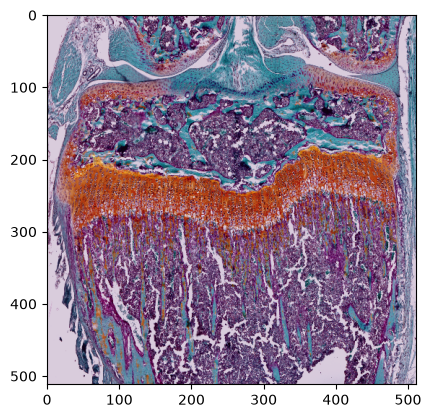

In [42]:
background = plt.imread("/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png")
bg_resized = cv2.resize(background, (512, 512), interpolation=cv2.INTER_LINEAR)
germinal = plt.imread('/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena/Germinal.png')
plt.imshow(bg_resized)
plt.imshow(germinal, alpha=0.2)
plt.show()

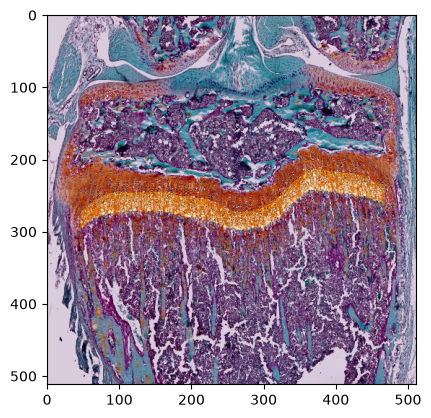

In [43]:
background = plt.imread("/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png")
bg_resized = cv2.resize(background, (512, 512), interpolation=cv2.INTER_LINEAR)
columnar = plt.imread('/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena/Columnar.png')
plt.imshow(bg_resized)
plt.imshow(columnar, alpha=0.2)
plt.show()

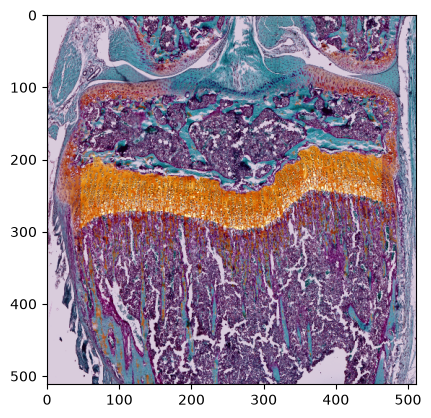

In [44]:
background = plt.imread("/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png")
bg_resized = cv2.resize(background, (512, 512), interpolation=cv2.INTER_LINEAR)
GP = plt.imread('/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena/GP.png')
plt.imshow(bg_resized)
plt.imshow(GP, alpha=0.2)
plt.show()

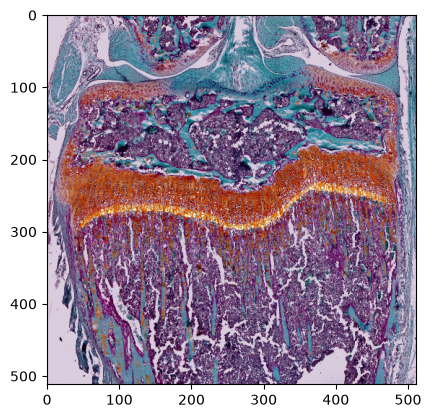

In [45]:
background = plt.imread("/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png")
bg_resized = cv2.resize(background, (512, 512), interpolation=cv2.INTER_LINEAR)
hypertrophic = plt.imread('/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena/Hypertrophic.png')
plt.imshow(bg_resized)
plt.imshow(hypertrophic, alpha=0.2)
plt.show()

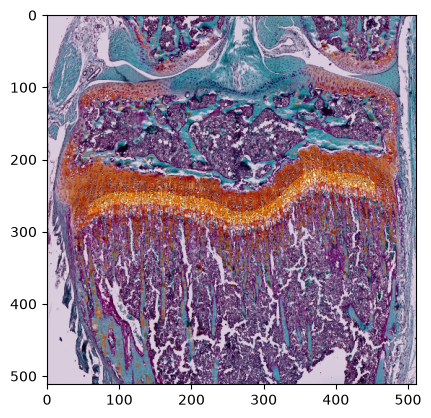

In [40]:
background = plt.imread("/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png")
bg_resized = cv2.resize(background, (512, 512), interpolation=cv2.INTER_LINEAR)
prehypertrophic = plt.imread('/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena/Pre_hypertrophic.png')
plt.imshow(bg_resized)
plt.imshow(prehypertrophic, alpha=0.2)
plt.show()

In [8]:
import os
import cv2
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

background_path = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png"
)

measure_dir = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2"
)

output_dir = os.path.join(
    measure_dir,
    "Overlaps_v2"
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# ZONE MASKS
# ============================================================

zone_names = [
    "Columnar",
    "Germinal",
    "GP",
    "Hypertrophic",
    "Pre_hypertrophic",
]


# ============================================================
# LOAD BACKGROUND
# ============================================================

background = plt.imread(background_path)

# Resize background to mask/model size
bg_resized = cv2.resize(
    background,
    (512, 512),
    interpolation=cv2.INTER_LINEAR
)


# ============================================================
# CREATE AND SAVE OVERLAPS
# ============================================================

for zone_name in zone_names:

    mask_path = os.path.join(
        measure_dir,
        f"{zone_name}.png"
    )

    mask = plt.imread(mask_path)

    # --------------------------------------------
    # Make figure exactly image-shaped
    # --------------------------------------------
    fig = plt.figure(
        figsize=(5.12, 5.12),
        dpi=100
    )

    ax = fig.add_axes([0, 0, 1, 1])

    # Background
    ax.imshow(bg_resized)

    # Zone overlay
    # Mask zero-valued background so only zone appears
    masked_zone = np.ma.masked_where(
        mask == 0,
        mask
    )

    ax.imshow(
        masked_zone,
        alpha=0.3,
        cmap="viridis"
    )

    # Remove axis, borders, etc.
    ax.axis("off")

    # --------------------------------------------
    # Save
    # --------------------------------------------
    output_path = os.path.join(
        output_dir,
        f"{zone_name}_overlap.png"
    )

    plt.savefig(
        output_path,
        dpi=100,
        bbox_inches=None,
        pad_inches=0
    )

    plt.close(fig)

    print(f"Saved: {output_path}")

Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Overlaps_v2/Columnar_overlap.png
Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Overlaps_v2/Germinal_overlap.png
Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Overlaps_v2/GP_overlap.png
Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Overlaps_v2/Hypertrophic_overlap.png
Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Overlaps_v2/Pre_hypertrophic_overlap.png


Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Contours_v2/Columnar_contour.png (1 contours)


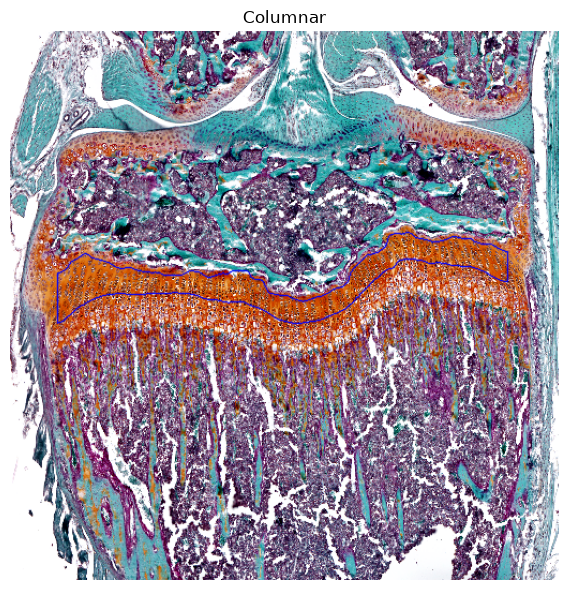

Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Contours_v2/Germinal_contour.png (5 contours)


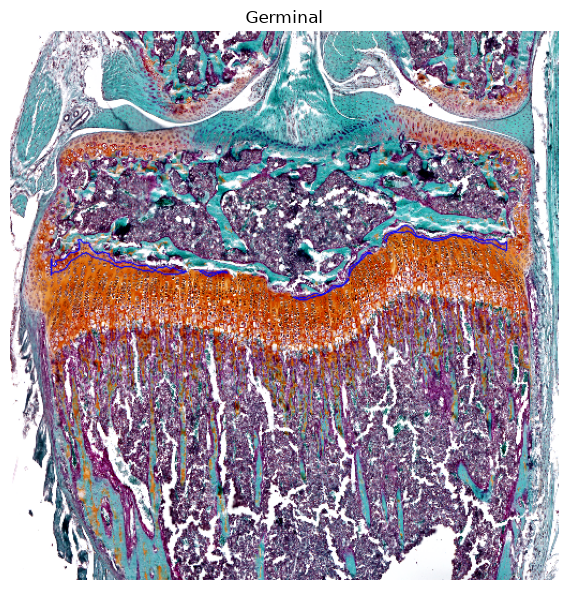

Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Contours_v2/GP_contour.png (1 contours)


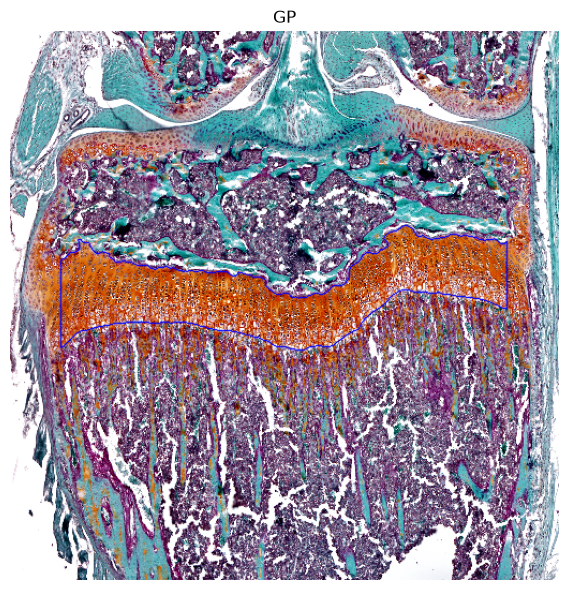

Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Contours_v2/Hypertrophic_contour.png (1 contours)


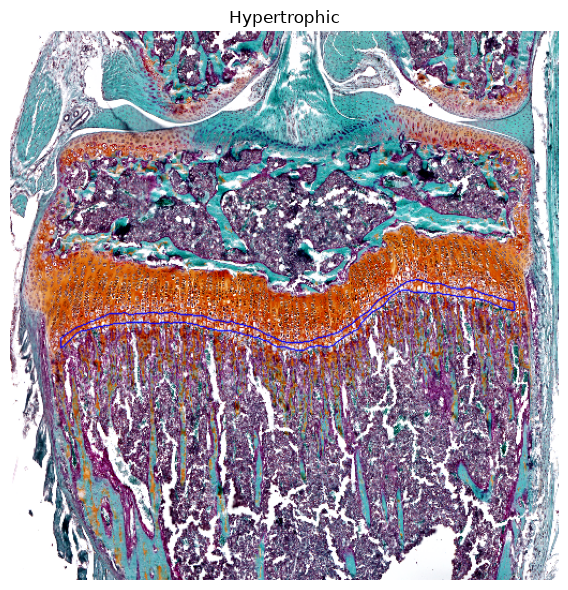

Saved: /home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/Contours_v2/Pre_hypertrophic_contour.png (1 contours)


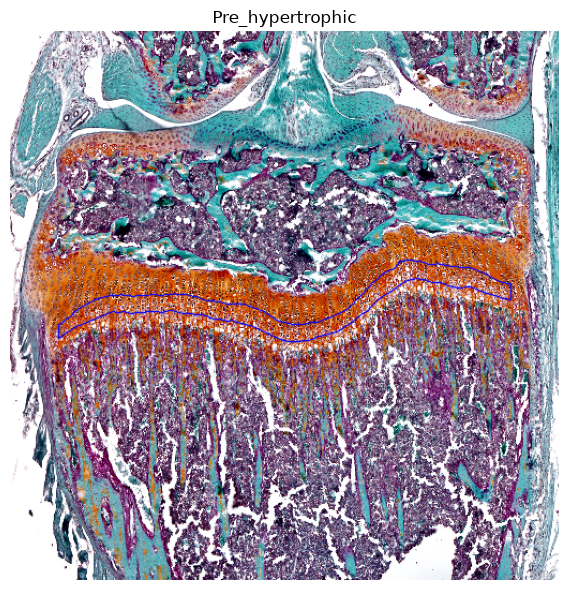

In [ ]:
# Individual zone visualizations with contour outline

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

background_path = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png"
)

measure_dir = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2"
)

output_dir = os.path.join(
    measure_dir,
    "Contours_v2"
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# SETTINGS
# ============================================================

zone_names = [
    "Columnar",
    "Germinal",
    "GP",
    "Hypertrophic",
    "Pre_hypertrophic",
]

IMAGE_SIZE = (512, 512)

CONTOUR_COLOR = (255, 0, 0)  # Red (RGB)
CONTOUR_THICKNESS = 1

# Remove tiny disconnected regions
MIN_CONTOUR_AREA = 20


# ============================================================
# LOAD BACKGROUND
# ============================================================

background = cv2.imread(
    background_path,
    cv2.IMREAD_COLOR
)

if background is None:
    raise FileNotFoundError(background_path)

bg_resized = cv2.resize(
    background,
    IMAGE_SIZE,
    interpolation=cv2.INTER_LINEAR
)


# ============================================================
# CREATE AND SAVE CONTOUR OVERLAYS
# ============================================================

for zone_name in zone_names:

    mask_path = os.path.join(
        measure_dir,
        f"{zone_name}.png"
    )

    # --------------------------------------------------------
    # Load binary mask
    # --------------------------------------------------------
    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        print(f"Missing mask: {mask_path}")
        continue

    mask = cv2.resize(
        mask,
        IMAGE_SIZE,
        interpolation=cv2.INTER_NEAREST
    )

    binary_mask = (mask > 0).astype(np.uint8) * 255

    # --------------------------------------------------------
    # Find contours
    # --------------------------------------------------------
    contours, _ = cv2.findContours(
        binary_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    contours = [
        contour
        for contour in contours
        if cv2.contourArea(contour) >= MIN_CONTOUR_AREA
    ]

    # --------------------------------------------------------
    # Draw red contours on original image
    # --------------------------------------------------------
    overlay = bg_resized.copy()

    cv2.drawContours(
        overlay,
        contours,
        contourIdx=-1,
        color=(255, 0, 0),  # Red in OpenCV BGR
        thickness=CONTOUR_THICKNESS,
        lineType=cv2.LINE_AA
    )

    # --------------------------------------------------------
    # Save image
    # --------------------------------------------------------
    output_path = os.path.join(
        output_dir,
        f"{zone_name}_contour.png"
    )

    cv2.imwrite(output_path, overlay)

    print(
        f"Saved: {output_path} "
        f"({len(contours)} contours)"
    )

    # --------------------------------------------------------
    # Optional visualization
    # --------------------------------------------------------
    plt.figure(figsize=(6, 6))

    plt.imshow(
        cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
    )

    plt.title(zone_name)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

background_path = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png"
)

measure_dir = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena"
)

output_dir = os.path.join(
    measure_dir,
    "Overlaps"
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# ZONE MASKS
# ============================================================

zone_names = [
    "Columnar",
    "Germinal",
    "GP",
    "Hypertrophic",
    "Pre_hypertrophic",
]


# ============================================================
# LOAD BACKGROUND
# ============================================================

background = plt.imread(background_path)

# Resize background to mask/model size
bg_resized = cv2.resize(
    background,
    (512, 512),
    interpolation=cv2.INTER_LINEAR
)


# ============================================================
# CREATE AND SAVE OVERLAPS
# ============================================================

for zone_name in zone_names:

    mask_path = os.path.join(
        measure_dir,
        f"{zone_name}.png"
    )

    mask = plt.imread(mask_path)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

measure_dir = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2"
)

signal_path = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png"
)

vis_dir = os.path.join(
    measure_dir,
    "Measurement_visualization"
)

os.makedirs(vis_dir, exist_ok=True)

output_csv = os.path.join(
    measure_dir,
    "zone_measurements.csv"
)


# ============================================================
# SETTINGS
# ============================================================

zone_names = [
    "Columnar",
    "Germinal",
    "GP",
    "Hypertrophic",
    "Pre_hypertrophic",
]

PIXEL_SIZE_UM = 3.45

# The zone masks already exclude 5% from each horizontal edge.
# Do not apply a second thickness-analysis trim.
TRIM_FRACTION = 0.00


# ============================================================
# LOAD SIGNAL
# ============================================================

signal_bgr = cv2.imread(
    signal_path,
    cv2.IMREAD_COLOR
)

if signal_bgr is None:
    raise FileNotFoundError(signal_path)


# ============================================================
# RESULTS
# ============================================================

results = []


# ============================================================
# PROCESS EACH ZONE
# ============================================================

for zone_name in zone_names:

    print("\n" + "=" * 70)
    print(f"Processing: {zone_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Load mask
    # --------------------------------------------------------

    mask_path = os.path.join(
        measure_dir,
        f"{zone_name}.png"
    )

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        print(f"Missing mask: {mask_path}")
        continue

    binary_mask = mask > 0

    H, W = binary_mask.shape


    # --------------------------------------------------------
    # Resize signal
    # --------------------------------------------------------

    signal = cv2.resize(
        signal_bgr,
        (W, H),
        interpolation=cv2.INTER_LINEAR
    )


    # ========================================================
    # MASK COORDINATES
    # ========================================================

    ys, xs = np.where(binary_mask)

    if len(xs) == 0:
        print("Empty mask.")
        continue


    # ========================================================
    # AREA
    # ========================================================

    area_px = int(
        binary_mask.sum()
    )

    area_um2 = (
        area_px *
        PIXEL_SIZE_UM ** 2
    )


    # ========================================================
    # FULL WIDTH
    # ========================================================

    x_min = int(xs.min())
    x_max = int(xs.max())

    full_width_px = (
        x_max -
        x_min +
        1
    )

    full_width_um = (
        full_width_px *
        PIXEL_SIZE_UM
    )


    # ========================================================
    # USE THE EXISTING 5%-PER-EDGE ZONE RANGE
    # ========================================================

    trim_px = int(
        round(
            full_width_px *
            TRIM_FRACTION
        )
    )

    trunc_x_min = (
        x_min +
        trim_px
    )

    trunc_x_max = (
        x_max -
        trim_px
    )


    truncated_width_px = (
        trunc_x_max -
        trunc_x_min +
        1
    )

    truncated_width_um = (
        truncated_width_px *
        PIXEL_SIZE_UM
    )


    # ========================================================
    # LOCAL ZONE THICKNESS
    # ========================================================

    thicknesses_px = []

    # Store boundaries for visualization
    thickness_x = []
    thickness_top = []
    thickness_bottom = []


    for x in range(
        trunc_x_min,
        trunc_x_max + 1
    ):

        # Find zone pixels at this x-column
        y_coords = np.where(
            binary_mask[:, x]
        )[0]

        if len(y_coords) == 0:
            continue


        y_top = int(
            y_coords.min()
        )

        y_bottom = int(
            y_coords.max()
        )


        # Local vertical thickness
        thickness = (
            y_bottom -
            y_top +
            1
        )


        thicknesses_px.append(
            thickness
        )

        thickness_x.append(
            x
        )

        thickness_top.append(
            y_top
        )

        thickness_bottom.append(
            y_bottom
        )


    thicknesses_px = np.array(
        thicknesses_px,
        dtype=np.float32
    )


    # ========================================================
    # THICKNESS STATISTICS
    # ========================================================

    mean_thickness_px = float(
        np.mean(thicknesses_px)
    )

    median_thickness_px = float(
        np.median(thicknesses_px)
    )

    std_thickness_px = float(
        np.std(thicknesses_px)
    )

    min_thickness_px = float(
        np.min(thicknesses_px)
    )

    max_thickness_px = float(
        np.max(thicknesses_px)
    )


    # Convert to micrometers
    mean_thickness_um = (
        mean_thickness_px *
        PIXEL_SIZE_UM
    )

    median_thickness_um = (
        median_thickness_px *
        PIXEL_SIZE_UM
    )

    std_thickness_um = (
        std_thickness_px *
        PIXEL_SIZE_UM
    )

    min_thickness_um = (
        min_thickness_px *
        PIXEL_SIZE_UM
    )

    max_thickness_um = (
        max_thickness_px *
        PIXEL_SIZE_UM
    )


    # ========================================================
    # SIGNAL STRENGTH
    # ========================================================

    signal_rgb = cv2.cvtColor(
        signal,
        cv2.COLOR_BGR2RGB
    )

    signal_gray = cv2.cvtColor(
        signal,
        cv2.COLOR_BGR2GRAY
    )


    zone_rgb = signal_rgb[
        binary_mask
    ]

    zone_gray = signal_gray[
        binary_mask
    ]


    mean_r = float(
        np.mean(zone_rgb[:, 0])
    )

    mean_g = float(
        np.mean(zone_rgb[:, 1])
    )

    mean_b = float(
        np.mean(zone_rgb[:, 2])
    )

    mean_gray = float(
        np.mean(zone_gray)
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    results.append({

        "Zone":
            zone_name,

        # Area
        "Area_px":
            area_px,

        "Area_um2":
            area_um2,

        # Full width
        "Full_width_px":
            full_width_px,

        "Full_width_um":
            full_width_um,

        # Analyzed width after 5% removal at each edge
        "Truncated_width_px":
            truncated_width_px,

        "Truncated_width_um":
            truncated_width_um,

        # Thickness
        "Mean_thickness_px":
            mean_thickness_px,

        "Mean_thickness_um":
            mean_thickness_um,

        "Median_thickness_px":
            median_thickness_px,

        "Median_thickness_um":
            median_thickness_um,

        "Std_thickness_px":
            std_thickness_px,

        "Std_thickness_um":
            std_thickness_um,

        "Min_thickness_px":
            min_thickness_px,

        "Min_thickness_um":
            min_thickness_um,

        "Max_thickness_px":
            max_thickness_px,

        "Max_thickness_um":
            max_thickness_um,

        # Signal
        "Mean_signal_gray":
            mean_gray,

        "Mean_signal_R":
            mean_r,

        "Mean_signal_G":
            mean_g,

        "Mean_signal_B":
            mean_b,
    })


    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Area: "
        f"{area_px:,} px² | "
        f"{area_um2:,.2f} µm²"
    )

    print(
        f"Full width: "
        f"{full_width_px} px | "
        f"{full_width_um:.2f} µm"
    )

    print(
        f"Analyzed width (5% removed each edge): "
        f"{truncated_width_px} px | "
        f"{truncated_width_um:.2f} µm"
    )

    print(
        f"Mean thickness: "
        f"{mean_thickness_px:.2f} px | "
        f"{mean_thickness_um:.2f} µm"
    )

    print(
        f"Median thickness: "
        f"{median_thickness_px:.2f} px | "
        f"{median_thickness_um:.2f} µm"
    )

    print(
        f"Thickness range: "
        f"{min_thickness_px:.1f} - "
        f"{max_thickness_px:.1f} px"
    )

    print(
        f"Mean signal: "
        f"{mean_gray:.2f}"
    )


    # ========================================================
    # VISUALIZATION
    # ========================================================

    vis = signal.copy()


    # --------------------------------------------------------
    # RED: zone contour
    # --------------------------------------------------------

    binary_uint8 = (
        binary_mask.astype(
            np.uint8
        ) * 255
    )

    contours, _ = cv2.findContours(
        binary_uint8,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        vis,
        contours,
        -1,
        (0, 0, 255),
        2,
        cv2.LINE_AA
    )


    # --------------------------------------------------------
    # BLUE: truncated width boundaries
    # --------------------------------------------------------

    cv2.line(
        vis,
        (trunc_x_min, 0),
        (trunc_x_min, H - 1),
        (255, 0, 0),
        2
    )

    cv2.line(
        vis,
        (trunc_x_max, 0),
        (trunc_x_max, H - 1),
        (255, 0, 0),
        2
    )


    # --------------------------------------------------------
    # GREEN: visualize local thickness
    #
    # Draw every 15th column so visualization
    # does not become too crowded.
    # --------------------------------------------------------

    for i in range(
        0,
        len(thickness_x),
        15
    ):

        x = thickness_x[i]

        y1 = thickness_top[i]
        y2 = thickness_bottom[i]

        cv2.line(
            vis,
            (x, y1),
            (x, y2),
            (0, 255, 0),
            1,
            cv2.LINE_AA
        )


    # ========================================================
    # PLOT
    # ========================================================

    vis_rgb = cv2.cvtColor(
        vis,
        cv2.COLOR_BGR2RGB
    )

    fig, ax = plt.subplots(
        figsize=(9, 9)
    )

    ax.imshow(
        vis_rgb
    )


    info = (

        f"Area\n"
        f"{area_px:,} px²\n"
        f"{area_um2:,.1f} µm²\n\n"

        f"Width (5% removed each edge)\n"
        f"{truncated_width_px} px\n"
        f"{truncated_width_um:.1f} µm\n\n"

        f"Zone thickness\n"
        f"Mean: {mean_thickness_px:.1f} px "
        f"/ {mean_thickness_um:.1f} µm\n"

        f"Median: {median_thickness_px:.1f} px "
        f"/ {median_thickness_um:.1f} µm\n"

        f"SD: {std_thickness_px:.1f} px "
        f"/ {std_thickness_um:.1f} µm\n\n"

        f"Mean signal: "
        f"{mean_gray:.2f}"
    )


    ax.text(
        0.02,
        0.98,
        info,
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.85
        )
    )


    ax.set_title(
        zone_name,
        fontsize=16
    )

    ax.axis("off")


    # Legend
    ax.plot(
        [],
        [],
        color="red",
        linewidth=2,
        label="Zone boundary"
    )

    ax.plot(
        [],
        [],
        color="blue",
        linewidth=2,
        label="5% edge exclusion"
    )

    ax.plot(
        [],
        [],
        color="green",
        linewidth=2,
        label="Local thickness"
    )

    ax.legend(
        loc="lower right"
    )


    plt.tight_layout()


    # Save
    output_path = os.path.join(
        vis_dir,
        f"{zone_name}_measurement.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# SAVE CSV
# ============================================================

df = pd.DataFrame(
    results
)

df.to_csv(
    output_csv,
    index=False
)


print("\n")
print("=" * 100)
print("FINAL MEASUREMENTS")
print("=" * 100)

print(
    df.to_string(
        index=False
    )
)

print(
    f"\nSaved:\n{output_csv}"
)

Saved visualization:
/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2/All_zones_overlay.png


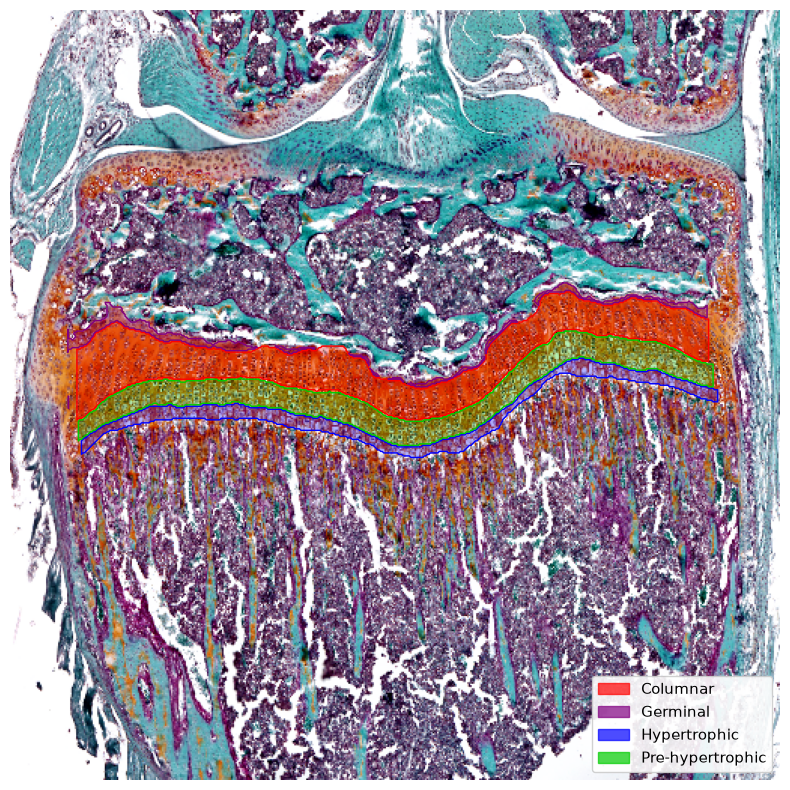

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# ============================================================
# PATHS
# ============================================================

background_path = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "Input/Testdata/Image/CCC_K10_M4_L1_Helena/sfo.png"
)

measure_dir = (
    "/home/yec23006/projects/research/KneeGrowthPlate/ZoneSeg/"
    "SemiSeparatedUnetFusion/Output_ch48_deepsuper/Measures_Helena_v2"
)

output_path = os.path.join(
    measure_dir,
    "All_zones_overlay.png"
)


# ============================================================
# SETTINGS
# ============================================================

zone_colors = {
    "Columnar": (1.0, 0.0, 0.0),           # Red
    "Germinal": (0.5, 0.0, 0.5),           # Purple
    "Hypertrophic": (0.0, 0.0, 1.0),       # Blue
    "Pre_hypertrophic": (0.0, 0.8, 0.0),   # Green
}

ALPHA = 0.30

IMAGE_SIZE = (512, 512)


# ============================================================
# LOAD SFO IMAGE
# ============================================================

background = plt.imread(
    background_path
)

background = cv2.resize(
    background,
    IMAGE_SIZE,
    interpolation=cv2.INTER_LINEAR
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(background)


# ============================================================
# OVERLAY EACH ZONE
# ============================================================

for zone_name, color in zone_colors.items():

    mask_path = os.path.join(
        measure_dir,
        f"{zone_name}.png"
    )

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        print(f"Missing mask: {mask_path}")
        continue

    mask = cv2.resize(
        mask,
        IMAGE_SIZE,
        interpolation=cv2.INTER_NEAREST
    )

    binary_mask = mask > 0


    # ========================================================
    # CREATE RGB COLOR OVERLAY
    # ========================================================

    overlay = np.zeros(
        (
            binary_mask.shape[0],
            binary_mask.shape[1],
            4
        ),
        dtype=np.float32
    )

    # RGB
    overlay[:, :, 0] = color[0]
    overlay[:, :, 1] = color[1]
    overlay[:, :, 2] = color[2]

    # Alpha only where mask exists
    overlay[:, :, 3] = (
        binary_mask.astype(np.float32)
        * ALPHA
    )


    # ========================================================
    # DISPLAY FILLED ZONE
    # ========================================================

    ax.imshow(
        overlay
    )


    # ========================================================
    # DRAW ZONE CONTOUR
    # ========================================================

    contours, _ = cv2.findContours(
        binary_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )


    # Convert OpenCV contour into matplotlib coordinates
    for contour in contours:

        if len(contour) < 2:
            continue

        contour = contour.squeeze()

        if contour.ndim != 2:
            continue

        # Close contour
        contour = np.vstack(
            [
                contour,
                contour[0]
            ]
        )

        ax.plot(
            contour[:, 0],
            contour[:, 1],
            color=color,
            linewidth=1
        )


# ============================================================
# LEGEND
# ============================================================

legend_elements = [

    Patch(
        facecolor=zone_colors["Columnar"],
        edgecolor=zone_colors["Columnar"],
        alpha=0.7,
        label="Columnar"
    ),

    Patch(
        facecolor=zone_colors["Germinal"],
        edgecolor=zone_colors["Germinal"],
        alpha=0.7,
        label="Germinal"
    ),

    Patch(
        facecolor=zone_colors["Hypertrophic"],
        edgecolor=zone_colors["Hypertrophic"],
        alpha=0.7,
        label="Hypertrophic"
    ),

    Patch(
        facecolor=zone_colors["Pre_hypertrophic"],
        edgecolor=zone_colors["Pre_hypertrophic"],
        alpha=0.7,
        label="Pre-hypertrophic"
    ),
]


ax.legend(
    handles=legend_elements,
    loc="lower right",
    fontsize=11,
    framealpha=0.9
)


# ============================================================
# DISPLAY
# ============================================================

ax.axis("off")

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0
)
print(
    f"Saved visualization:\n"
    f"{output_path}"
)

plt.show()
plt.close()

In [ ]:
# With contour outline — save the total five-zone visualization

from pathlib import Path
import sys
from IPython.display import display

cwd = Path.cwd().resolve()
project_root = next(
    (path for path in (cwd, *cwd.parents) if (path / "KneeZoneSeg" / "UI").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Run this notebook inside the ZoneSeg project.")
ui_dir = project_root / "KneeZoneSeg" / "UI"
if str(ui_dir) not in sys.path:
    sys.path.insert(0, str(ui_dir))

from zone_metrics import SIDE_EXCLUSION, analyze_zones, export_zone_csv
from zone_visualization import render_all_zones, save_zone_visualizations

zone_results = analyze_zones(
    mask_dir,
    image_path,
    side_exclusion=SIDE_EXCLUSION,  # 5% left + 5% right
    pixel_size_um=3.45,
)
total_output_dir = (
    Path(mask_dir).parent / "Zone_analysis" / Path(mask_dir).name
)
save_zone_visualizations(image_path, zone_results, total_output_dir)
export_zone_csv(zone_results, total_output_dir / "zone_measurements.csv")

total_visualization = render_all_zones(image_path, zone_results)
total_visualization_path = (
    total_output_dir / "visualizations" / "All_zones_contour_overlay.png"
)
total_visualization.save(total_visualization_path)
print(f"Saved total contour visualization: {total_visualization_path}")
display(total_visualization)
